# §6 Preparation Design (Stage S6)

This section turns the findings of S3–S5 into **fourteen switchable preparation steps** (P01–P14),
groups them into **six reporting blocks** (B1–B6) and fixes the **arms** that S7 compares:

* **M0** – the naive analyst: every column except id/design/label, blanket recode of 7/9/77/99/…,
  median imputation, one-hot encoding, logistic regression. Leakage included.
* **M1** – M0 plus the availability rule only (P03). *Minimal but honest.*
* **S** – all steps on (P14 WHtR stays a separate arm).

The headline "minimal vs systematic" comparison is **M1 vs S** (same model); **M0 → M1 is the
leak gate**. The pre-registered hypotheses for the blocks are locked here, before any ablation.

Contents: 1 inputs · 2 step catalogue · 3 B1 integrity · 4 B2 admissibility · 5 B3 redundancy ·
6 B4 missingness · 7 B5 representation · 8 B6 weights · 9 arms · 10 pipeline assertions ·
11 hypotheses and lock · 12 decisions and storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib, json, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)
OUT = C.RESULTS_DIR / "S6"
OUT.mkdir(parents=True, exist_ok=True)
S6 = {}

## 1 Inputs
**Why.** Every preparation decision must happen *inside* the model pipeline so that it is refitted in
each training fold. The pipeline therefore receives the **raw** cohort (XPT artefact not repaired,
no sentinel recode) and the naive column set. The frozen evaluation label `L_comb` comes from the
per-variable cohort (S5). Descriptive design statistics below use the **training part** only: the
20 % hold-out (label × race stratified, `evalkit.make_holdout`, created once and persisted) is not
looked at until S9.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
train_idx, test_idx = ek.make_holdout(clean)
raw_tr, clean_tr = raw.iloc[train_idx].reset_index(drop=True), clean.iloc[train_idx].reset_index(drop=True)
X1, X2 = P.raw_feature_frame(raw, 1), P.raw_feature_frame(raw, 2)
X1_tr, X2_tr = X1.iloc[train_idx].reset_index(drop=True), X2.iloc[train_idx].reset_index(drop=True)
spec = P._spec_by_var()
roles = spec.loc[X2.columns, ["role", "admissible", "dtype"]].value_counts(["role", "admissible"]).rename("n_columns")
print(f"cohort {len(raw):,} rows; training part {len(train_idx):,}, hold-out {len(test_idx):,} (not used here)")
print(f"naive feature frame: Tier 1 {X1.shape[1]} columns, Tier 2 {X2.shape[1]} columns")
print(roles.to_string())
S6["inputs"] = dict(n_cohort=len(raw), n_train=len(train_idx), n_holdout=len(test_idx),
                    n_raw_cols_t1=X1.shape[1], n_raw_cols_t2=X2.shape[1])

cohort 5,730 rows; training part 4,584, hold-out 1,146 (not used here)
naive feature frame: Tier 1 52 columns, Tier 2 54 columns
role           admissible
feature        T1            30
leak           N              8
optional       N              5
audit          N              3
feature        T2             2
cohort_filter  N              2
redundancy     N              2
side           N              2


**So what.** A naive analyst hands the model 52 (Tier 1) or 54 (Tier 2) columns, and the role table shows
what that includes: leakage items (glucose, treatment, age at diagnosis, DIQ160/DIQ180),
audit-only variables (race, insurance, usual place of care), side and optional variables. Only the rows
with admissibility T1/T2 pass the S1 availability rule; everything else is a trap that M0 keeps on
purpose.

## 2 Step catalogue
**Why.** Each step has to be traceable to evidence and must say whether it learns from the data
(then it is fitted in-fold) and whether it could ever see the label (none may).

In [3]:
S4dir = C.RESULTS_DIR / "S4"
vif4 = pd.read_csv(S4dir / "vif_table.csv")
lin4 = pd.read_csv(S4dir / "linearity_tests.csv").set_index("variable")
sk4 = pd.read_csv(S4dir / "skew_table.csv")
auc5 = R.load_section("S5")["asian_bmi"]["auc"]
vraw = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vbp, vbm = vif4.loc[vif4["set"] == "bp_readings", "vif"], vif4.loc[vif4["set"] == "bp_means", "vif"]
sk_bmi = sk4.query("variable == 'BMXBMI' and subsample == 'cohort'")["skew_raw"].iloc[0]
sk_tg = sk4[(sk4["variable"] == "LBXTLG") & sk4["subsample"].str.startswith("fasting")]["skew_raw"].iloc[0]
gain = {g: auc5[f"NH {g}|WHtR \u2212 BMI (paired)"]["auc"] for g in ("Asian", "White")}
ev = {
    "P04": f"S4: 6 BP readings VIF {vbp.min():.1f}-{vbp.max():.1f} vs means {vbm.max():.1f}; PA skip pattern",
    "P05": f"S4: weight VIF {vraw['BMXWT']:.1f}, BMI {vraw['BMXBMI']:.1f}; keep BMI + waist",
    "P06": f"cohort: PIR missing {raw['INDFMPIR'].isna().mean():.1%}; MNAR-suspect list",
    "P08": f"S4: |skew| > 1 (BMI {sk_bmi:.2f}, TG {sk_tg:.2f} fasting)",
    "P11": f"prevalence {clean['L_comb'].mean():.1%}; balanced weights",
    "P13": "S4: RCS LR chi2 " + ", ".join(f"{lab} {lin4.loc[v, 'chi2']:.1f}" for v, lab in
                                           (("RIDAGEYR", "age"), ("BMXBMI", "BMI"), ("LBDHDD", "HDL"), ("LBXTC", "TC"))),
    "P14": f"S5: WHtR-BMI AUC gain Asian {gain['Asian']:+.3f} vs White {gain['White']:+.3f}",
}
catalogue = pd.DataFrame([
    ("P01", "xpt_zero_fix", "B1", "stateless", "S3: zero stored as 5.4e-79; mask() keeps NaN"),
    ("P02", "sentinel_by_var", "B1", "stateless", "S3: blanket recode wipes valid values; off = blanket (M0)"),
    ("P03", "admissibility", "B2", "stateless", "S1 availability rule; spec column `admissible`"),
    ("P04", "aggregate", "B3", "stateless", ev["P04"]),
    ("P05", "prune", "B3", "fitted in-fold (X)", ev["P05"]),
    ("P06", "missing_indicator", "B4", "stateless", ev["P06"]),
    ("P07", "topcode_flag", "B4", "stateless", "S2/S3: age top-coded 80, PIR 5"),
    ("P08", "yeo_johnson", "B5", "fitted in-fold (X)", ev["P08"]),
    ("P09", "scale", "B5", "fitted in-fold (X)", "L2 penalty is scale dependent; unscaled fits fail to converge"),
    ("P10", "rare_categories", "B5", "fitted in-fold (X)", "levels < 2 % grouped as infrequent"),
    ("P11", "class_weight", "B6a", "estimator", ev["P11"]),
    ("P12", "survey_weight", "B6b", "estimator", "S4: WTPH2YR for HbA1c cohort; mean 1"),
    ("P13", "splines", "B5", "fitted in-fold (X)", ev["P13"]),
    ("P14", "whtr", "(arm)", "stateless", ev["P14"]),
], columns=["step", "name", "block", "learns from", "evidence"])
assert list(catalogue["step"]) == list(P.STEPS)
assert all(P.STEP_BLOCK[s] == b or b == "(arm)" for s, b in zip(catalogue["step"], catalogue["block"]))
catalogue.to_csv(OUT / "step_catalogue.csv", index=False)
print(catalogue.to_string(index=False))

step              name block        learns from                                                      evidence
 P01      xpt_zero_fix    B1          stateless                  S3: zero stored as 5.4e-79; mask() keeps NaN
 P02   sentinel_by_var    B1          stateless     S3: blanket recode wipes valid values; off = blanket (M0)
 P03     admissibility    B2          stateless                S1 availability rule; spec column `admissible`
 P04         aggregate    B3          stateless  S4: 6 BP readings VIF 8.8-11.7 vs means 1.6; PA skip pattern
 P05             prune    B3 fitted in-fold (X)               S4: weight VIF 95.7, BMI 97.6; keep BMI + waist
 P06 missing_indicator    B4          stateless                  cohort: PIR missing 12.8%; MNAR-suspect list
 P07      topcode_flag    B4          stateless                                S2/S3: age top-coded 80, PIR 5
 P08       yeo_johnson    B5 fitted in-fold (X)                    S4: |skew| > 1 (BMI 1.22, TG 6.62 fasting)
 P09      

**So what.** Seven steps are stateless, five are fitted on the training fold's **features** only, and two act
on the estimator. No step uses the label – section 10 tests this with a random label. Two steps are
*switches* rather than on/off toggles because M0 already does something at that point: P02 (off = blanket
recode) and P10 (off = plain one-hot).

## 3 B1 integrity: XPT zeros and sentinel codes
**Why.** S3 showed that the XPT reader turns stored zeros into 5.4e-79 and that a blanket
`replace({7, 9, 77, 99, ...}, NaN)` destroys valid measurements. The naive analyst also builds the
*label* from recoded data, so HbA1c values of exactly 7.0 % and 9.0 % disappear before `L_comb` is formed.

In [4]:
x_fixed = P.XptZeroFix().transform(X1_tr)
num = X1_tr.select_dtypes("number")
art = ((num.abs() < C.XPT_ZERO_EPS) & num.notna() & (num != 0)).sum()
n_artefact = int(art.sum())
agg_off = P.Aggregate().transform(P.Sentinels("per_variable").transform(X1_tr))  # P01 off, P04 on
agg_on = P.Aggregate().transform(P.Sentinels("per_variable").transform(x_fixed))
pa_lost = int((agg_on["pa_mod_min_wk"].eq(0) & agg_off["pa_mod_min_wk"].isna()).sum())
pv = P.Sentinels("per_variable").transform(x_fixed)
bl = P.Sentinels("blanket").transform(x_fixed)
wiped = (bl.isna() & pv.notna()).sum()
wiped = wiped[wiped > 0].sort_values(ascending=False)
y_naive_all = P.training_label(raw, P.ALL_OFF)
y_true_all = clean["L_comb"].to_numpy()
flips = int((y_naive_all != y_true_all).sum())
a1c_lost = int((clean["L_A1c"].eq(1) & raw["LBXGH"].isin(io.BLANKET_CODES)).sum())
print(f"P01: {n_artefact:,} artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {art[art > 0].to_dict()}")
print(f"P01 x P04: without the fix, 'frequency == 0' fails, so {pa_lost:,} non-exercisers get NaN instead of 0 weekly minutes")
print(f"P02: blanket recode wipes {int(wiped.sum()):,} valid values in {len(wiped)} feature columns (training part):")
print(wiped.head(12).to_string())
print(f"label: L_comb positives per-variable {y_true_all.sum()}, naive {y_naive_all.sum()}; "
      f"{a1c_lost} HbA1c positives lost, {flips} L_comb labels flip (whole cohort)")
assert flips == 6 and a1c_lost == 29 and y_true_all.sum() == 971
S6["B1"] = dict(n_artefact_cells_train_t1=n_artefact, artefact_by_column=art[art > 0].to_dict(), pa_zero_lost_without_p01=pa_lost, n_blanket_wiped_train_t1=int(wiped.sum()),
                wiped_by_column=wiped.to_dict(), label_flips=flips, a1c_positives_lost=a1c_lost,
                naive_lcomb_pos=int(y_naive_all.sum()))

P01: 3,630 artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {'INDFMPIR': 38, 'INDFMMPI': 93, 'PAD790Q': 939, 'PAD810Q': 2556, 'PAD680': 4}
P01 x P04: without the fix, 'frequency == 0' fails, so 939 non-exercisers get NaN instead of 0 weekly minutes
P02: blanket recode wipes 2,003 valid values in 24 feature columns (training part):
PAD790Q     298
RIDRETH3    291
BPXODI2     187
BPXODI1     187
BPXODI3     164
BPXOPLS2    123
BPXOPLS1    120
BPXOPLS3    118
LBXGLU       98
RIDAGEYR     54
LBDLDL       50
BPXOSY1      47
label: L_comb positives per-variable 971, naive 965; 29 HbA1c positives lost, 6 L_comb labels flip (whole cohort)


**So what.** The zero artefact sits almost entirely in the activity frequencies and the income ratio. As a number it is
harmless (5.4e-79 ≈ 0), but every *equality test* on zero fails: without P01 the skip-pattern rule of P04
("0 sessions → 0 minutes") silently turns the non-exercisers printed above into missing values. P01 is a
fidelity fix whose cost only shows downstream. The blanket recode is not harmless: it deletes valid
answers (e.g. 7 sessions of activity per week, 77-year-olds, a diastolic pressure of 77) and costs the
naive label 29 HbA1c-based positives, of which 6 are not rescued by self-report. These numbers agree with the
profiling in §3 (1,496 wiped cells were counted there on 20 continuous candidates in the whole cohort; here the count
refers to the model's feature frame in the training part). Expected model effect: small (hypothesis B1).

## 4 B2 admissibility (availability rule)
**Why.** The use case is screening *before any glucose test*. A feature is admissible only if it exists at
that moment (S1). The rule is applied from the spec, not by judging variables one at a time.

In [5]:
rows = []
for tier, X in ((1, X1), (2, X2)):
    kept = P.Admissibility(tier).transform(X).columns
    for c in X.columns:
        if c not in kept:
            rows.append({"tier": tier, "column": c, "role": spec.loc[c, "role"],
                         "admissible": spec.loc[c, "admissible"], "reason": spec.loc[c, "admiss_reason"][:70]})
p03 = pd.DataFrame(rows)
p03.to_csv(OUT / "p03_excluded.csv", index=False)
excl_t1 = set(p03.loc[p03["tier"] == 1, "column"])
missing_from_rule = [v for v in P.P03_EXCLUDED if v in X1.columns and v not in excl_t1]
assert not missing_from_rule, missing_from_rule
assert set(P.P03_EXCLUDED) - set(X1.columns) == {"LBXGH"}  # LBXGH defines the label, never a feature
assert (p03["admissible"] == "N").all()
kept_t1 = sorted(P.Admissibility(1).transform(X1).columns)
print(f"P03 removes {len(excl_t1)} of {X1.shape[1]} Tier-1 columns; kept ({len(kept_t1)}): {kept_t1}")
print(p03[p03["tier"] == 1].groupby("role")["column"].apply(list).to_string())
S6["B2"] = dict(n_excluded_t1=len(excl_t1), n_kept_t1=len(kept_t1), kept_t1=kept_t1,
                excluded_t1=sorted(excl_t1))

P03 removes 22 of 52 Tier-1 columns; kept (30): ['BMXARMC', 'BMXBMI', 'BMXHIP', 'BMXHT', 'BMXWAIST', 'BMXWT', 'BPQ020', 'BPQ080', 'BPXODI1', 'BPXODI2', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3', 'BPXOSY1', 'BPXOSY2', 'BPXOSY3', 'DMDEDUC2', 'DMDMARTZ', 'INDFMPIR', 'PAD680', 'PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820', 'RIAGENDR', 'RIDAGEYR', 'SMQ020']
role
audit                                                   [RIDRETH3, HIQ011, HUQ030]
cohort_filter                                                 [RIDSTATR, RIDEXPRG]
leak             [LBXGLU, DID040, DIQ160, DIQ180, DIQ050, DID060, DIQ060U, DIQ070]
optional                             [MCQ160B, MCQ160C, MCQ160D, MCQ160E, MCQ160F]
redundancy                                                    [INDFMMPI, INDFMMPC]
side                                                              [LBXTLG, LBDLDL]


**So what.** P03 removes every column with admissibility `N`: the glucose test, treatment and diagnosis
history (leakage), race, insurance and usual place of care (audit-only by design), and optional/side
variables outside the frozen T1 list. The explicit S1 list (LBXGLU, DIQ050, DIQ070, DID040, DID060,
DIQ160, DIQ180, RIDRETH3, HIQ011, HUQ030) is contained in it (asserted). BPQ020 (told high blood pressure) and
BPQ080 (told high cholesterol) pass the timing rule but are traces of earlier care; the **T1-minus-care** arm
removes them so S7 can measure how much of the signal is "being known to the health system".

## 5 B3 redundancy: aggregation and pruning
**Why.** Six blood-pressure readings measure the same thing (VIF 8.8–11.7, S4), and weight, height and BMI
are linked by a formula (VIF ≈ 96). The physical-activity block has a skip pattern: people who report
zero sessions are never asked how long a session lasts, so their duration is *structurally* missing – median
imputation would give a non-exerciser the median session length.

In [6]:
xpv = P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X1_tr))
skip_mod = int((xpv["PAD790Q"].eq(0) & xpv["PAD800"].isna()).sum())
skip_vig = int((xpv["PAD810Q"].eq(0) & xpv["PAD820"].isna()).sum())
med_mod = float(xpv["PAD800"].median())
agg = P.Aggregate().transform(P.Admissibility(1).transform(xpv))
pre = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04"]), 1)).fit_transform(X1_tr)
cont = P._continuous(pre)
vif_before = P.vif_table(pre[cont]).sort_values(ascending=False)
pr = P.VIFPrune().fit(pre)
vif_after = P.vif_table(pr.transform(pre)[[c for c in cont if c not in dict(pr.dropped_)]]).sort_values(ascending=False)
raw6 = P.vif_table(xpv[list(io.BP_SYS) + list(io.BP_DIA)])
vif_tab = pd.DataFrame({"vif_before_prune": vif_before, "vif_after_prune": vif_after}).round(2)
vif_tab.to_csv(OUT / "vif_in_pipeline.csv")
print(f"PA skip pattern: {skip_mod:,} with 0 moderate sessions and no duration (naive median would impute {med_mod:.0f} min); "
      f"{skip_vig:,} for vigorous")
print(f"weekly moderate minutes: median {agg['pa_mod_min_wk'].median():.0f}, share 0 = {agg['pa_mod_min_wk'].eq(0).mean():.1%}")
print(f"6 raw BP readings: VIF {raw6.min():.1f}-{raw6.max():.1f}")
print(f"P05 drops: {pr.dropped_}")
print(vif_tab.to_string())
S6["B3"] = dict(pa_skip_moderate=skip_mod, pa_skip_vigorous=skip_vig, pa_naive_median_minutes=med_mod,
                vif_bp_raw_min=float(raw6.min()), vif_bp_raw_max=float(raw6.max()),
                p05_dropped={c: v for c, v in pr.dropped_},
                vif_max_after=float(vif_after.max()))

PA skip pattern: 939 with 0 moderate sessions and no duration (naive median would impute 45 min); 2,556 for vigorous
weekly moderate minutes: median 120, share 0 = 20.5%
6 raw BP readings: VIF 8.7-11.7
P05 drops: [('BMXWT', 69.53177276876443)]
               vif_before_prune  vif_after_prune
BMXARMC                    5.26             5.25
BMXBMI                    62.29             9.72
BMXHIP                     5.10             5.07
BMXHT                     14.61             1.59
BMXWAIST                   6.24             6.08
BMXWT                     69.53              NaN
INDFMPIR                   1.10             1.10
PAD680                     1.09             1.09
RIDAGEYR                   1.65             1.65
bp_dia_mean                2.23             2.23
bp_sys_mean                2.35             2.35
pa_mod_min_wk              1.16             1.16
pa_vig_min_wk              1.17             1.17
pulse_mean                 1.24             1.24


**So what.** Averaging the readings removes the BP collinearity (6 readings VIF 8.7–11.7 → means ≈ 2.3), and converting activity into weekly minutes
turns the structural gap into a true zero for about a fifth of the training part instead of the median duration.
In-fold VIF pruning (threshold 10, BMI and waist protected) removes **weight** only (BMI VIF 62 → 9.7); height, hip and arm
circumference stay because their VIF is below 10 after weight is gone (O'Brien 2007: VIF alone is not a reason
to delete). L2 shrinkage is the second line of defence. Hypothesis B3 expects the same AUC but a more stable
BMI coefficient.

## 6 B4 missingness: indicators and top-codes
**Why.** A missing-value indicator only helps when missingness carries information (MNAR-suspect); under MAR
it can bias (Groenwold et al. 2012). We list candidates whose missingness has a plausible mechanism
(income refusal, exam not possible, no blood pressure / blood sample) and show how missingness relates to
the label in the training part (descriptive, `prior_exposure = descriptive_seen`).

In [7]:
agg2 = P.Aggregate().transform(P.Admissibility(2).transform(
    P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X2_tr))))
ytr = clean_tr["L_comb"].to_numpy()
mrows = []
for c in P.MNAR_SUSPECT:
    m = agg2[c].isna().to_numpy()
    mrows.append({"column": c, "n_missing": int(m.sum()), "share_missing": m.mean(),
                  "prev_if_missing": ytr[m].mean() if m.any() else np.nan, "prev_if_observed": ytr[~m].mean()})
mnar = pd.DataFrame(mrows).round(3)
mnar.to_csv(OUT / "mnar_candidates.csv", index=False)
n_age80 = int(xpv["RIDAGEYR"].eq(80).sum()); n_pir5 = int(xpv["INDFMPIR"].eq(5).sum())
print(mnar.to_string(index=False))
print(f"top-codes in training part: age 80 = {n_age80}, PIR 5 = {n_pir5}")
S6["B4"] = dict(mnar=mnar.set_index("column").to_dict("index"), n_age_top=n_age80, n_pir_top=n_pir5)

     column  n_missing  share_missing  prev_if_missing  prev_if_observed
   INDFMPIR        599          0.131            0.174             0.169
   BMXWAIST        205          0.045            0.298             0.164
bp_sys_mean        144          0.031            0.194             0.169
      LBXTC        216          0.047            0.199             0.168


top-codes in training part: age 80 = 255, PIR 5 = 1017


**So what.** The picture is uneven. Missing waist circumference is strongly informative (prevalence 29.8 % vs
16.4 % – waist is not measured when the exam is not possible, e.g. in very heavy or immobile people), whereas
missing income is almost uninformative for the label (17.4 % vs 16.9 %). An indicator can only exploit the
former, so the effect on discrimination is expected to be negligible, and the calibration benefit for people with
missing income (hypothesis B4) is now *less* likely than the design phase assumed. Because this table was seen
before the lock, B4 carries `prior_exposure = descriptive_seen`.
Top-coding turns "80" into "80 or older" and "5" into "5 or more"; the flags let the model treat the
boundary as a category instead of a number.

## 7 B5 representation: skewness, splines, scaling, rare levels
**Why.** S4 found monotone but curved relations for age and BMI (and HDL/TC in Tier 2) – a linear term
would be misspecified – and right-skewed variables. Splines keep the model a GLM; Yeo-Johnson is fitted in-fold
only on columns with |skew| > 1 that are not already splined.

In [8]:
pre_s = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)   # before encoding
yj = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s)
skew = pd.Series(yj.skew_).round(2).sort_values(key=abs, ascending=False)
after = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s).transform(pre_s)
skew_after = {c: float(pd.Series(after[c]).skew()) for c in yj.cols_}
cat_cols = [c for c in pre_s.columns if P._is_cat(pre_s, c)]
rare = {c: [str(k) for k, v in pre_s[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ] for c in cat_cols}
rare = {c: v for c, v in rare.items() if v}
pre_nop4 = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)
rare_nop4 = {c: [f"{k} ({v:.1%})" for k, v in pre_nop4[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ]
             for c in pre_nop4.columns if P._is_cat(pre_nop4, c)}
rare_nop4 = {c: v for c, v in rare_nop4.items() if v}
print("training-fold skewness (Tier 2, before P08):"); print(skew.to_string())
print(f"P08 transforms {yj.cols_}; skewness after: { {k: round(v, 2) for k, v in skew_after.items()} }")
print(f"P13 splines: {dict(P.SPLINE_COLS)} with {C.SPLINE_KW}")
print(f"P10 levels below {P.RARE_MIN_FREQ:.0%} with P04 on: {rare}; with P04 off: {rare_nop4}")
S6["B5"] = dict(skew=skew.to_dict(), yj_columns=yj.cols_, skew_after_yj=skew_after,
                spline_cols={k: list(v) for k, v in P.SPLINE_COLS.items()}, spline_kw=C.SPLINE_KW, rare_levels=rare, rare_levels_without_p04=rare_nop4)

training-fold skewness (Tier 2, before P08):


pa_vig_min_wk    12.14
pa_mod_min_wk     5.97
BMXHIP            1.13
bp_sys_mean       0.97
PAD680            0.79
BMXWAIST          0.63
BMXARMC           0.61
pulse_mean        0.51
bp_dia_mean       0.49
BMXHT             0.13
INDFMPIR         -0.04
P08 transforms ['BMXHIP', 'pa_mod_min_wk', 'pa_vig_min_wk']; skewness after: {'BMXHIP': 0.0, 'pa_mod_min_wk': -0.12, 'pa_vig_min_wk': 0.42}
P13 splines: {1: ('RIDAGEYR', 'BMXBMI'), 2: ('RIDAGEYR', 'BMXBMI', 'LBDHDD', 'LBXTC')} with {'n_knots': 4, 'degree': 3, 'knots': 'quantile', 'extrapolation': 'linear', 'include_bias': False}
P10 levels below 2% with P04 on: {}; with P04 off: {'PAD790U': ['Y (1.0%)'], 'PAD810U': ['Y (1.9%)']}


**So what.** Only the activity minutes and hip circumference exceed |skew| = 1 once BMI is splined; Yeo-Johnson
brings them close to symmetric. Note that in the *S-linear* arm BMI is not splined and is therefore
Yeo-Johnson transformed (skew 1.22 in S4). Splines add 5 basis columns per variable (B-spline basis, not a
restricted cubic spline). With P04 on, no admissible category falls below 2 % in the training part, so P10 is
inert in S and acts only as a guard against unseen levels in small folds. This depends on P04: without it the
activity *unit* columns (day / week / month / year) stay in the model and their rare levels (printed) are grouped by
P10 – so P10 matters only in arms that switch P04 off. For trees P08/P09 are monotone per column and must leave predictions unchanged (section 10).

## 8 B6 class and survey weights
**Why.** `class_weight='balanced'` (P11) trades calibration for sensitivity at the default threshold; survey
weights (P12, WTPH2YR, mean 1) make the fit target the population rather than the sample (60+ are
over-represented: 46.2 % vs 31.4 % weighted, S5).

In [9]:
w = P.survey_weights(raw_tr)
kish = float(w.sum() ** 2 / (w ** 2).sum())
print(f"training prevalence of L_comb: {ytr.mean():.3f}; balanced weights: positives x{0.5 / ytr.mean():.2f}, negatives x{0.5 / (1 - ytr.mean()):.2f}")
print(f"WTPH2YR / mean: min {w.min():.2f}, max {w.max():.2f}; Kish effective n {kish:,.0f} of {len(w):,} (deff {len(w) / kish:.2f})")
S6["B6"] = dict(train_prevalence=float(ytr.mean()), w_min=float(w.min()), w_max=float(w.max()),
                kish_neff=kish, kish_deff=len(w) / kish)

training prevalence of L_comb: 0.170; balanced weights: positives x2.95, negatives x0.60
WTPH2YR / mean: min 0.11, max 5.70; Kish effective n 2,968 of 4,584 (deff 1.54)


**So what.** Balanced class weights multiply each positive by about 3; probabilities will be inflated, so the
Brier score should worsen while discrimination stays (hypothesis B6a). The survey weights reduce the
effective sample size by about a third; hypothesis B6b expects at most a small loss in *unweighted* AUC.

## 9 Arms
**Why.** The comparison logic must be fixed before results exist: the cumulative path
M0 → +B2 (= M1) → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b (= S), leave-one-block-out arms S−Bk (the primary
block evidence), T1-minus-care, S-linear (splines off), S-linear-B3 (its coefficient-stability companion) and S+WHtR.

               P01  P02  P03  P04  P05  P06  P07  P08  P09  P10  P11  P12  P13  P14  NO_CARE  n_features_T1  n_features_T2
M0               0    0    0    0    0    0    0    0    0    0    0    0    0    0        0             88             90
M1               0    0    1    0    0    0    0    0    0    0    0    0    0    0        0             46             48
S                1    1    1    1    1    1    1    1    1    1    1    1    1    0        0             42             53
cum+B1           1    1    1    0    0    0    0    0    0    0    0    0    0    0        0             46             48
cum+B3           1    1    1    1    1    0    0    0    0    0    0    0    0    0        0             29             31
cum+B4           1    1    1    1    1    1    1    0    0    0    0    0    0    0        0             34             37
cum+B5           1    1    1    1    1    1    1    1    1    1    0    0    1    0        0             42             53
cum+B6a         

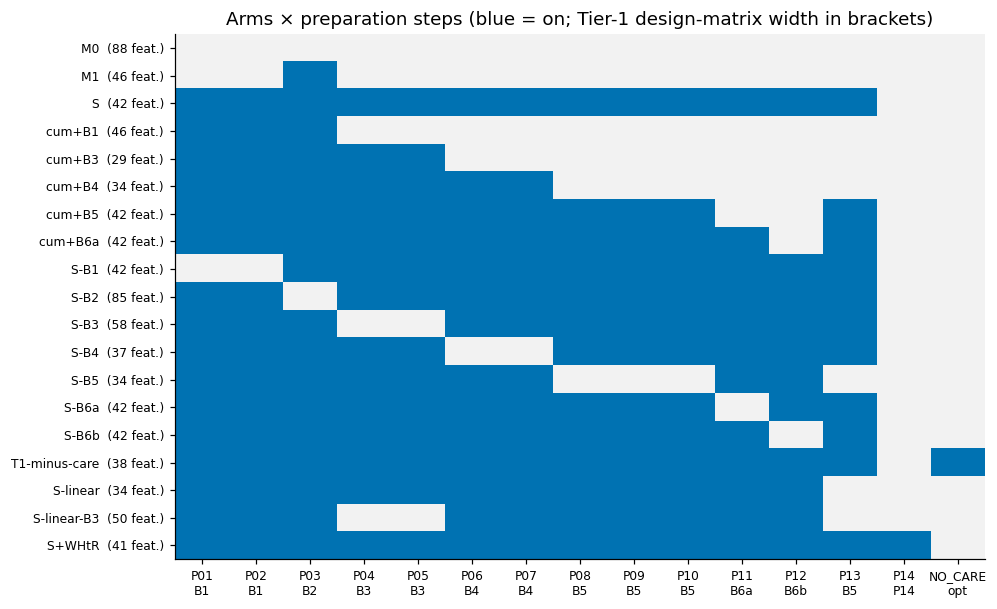

In [10]:
arms = P.arm_table()
arms.to_csv(OUT / "arm_table.csv")
nfeat = {}
for a, cfg in P.ARMS.items():
    for t, X in ((1, X1_tr), (2, X2_tr)):
        nfeat[(a, t)] = Pipeline(P.preprocessor_steps(cfg, t)).fit_transform(X).shape[1]
nfeat = pd.Series(nfeat).unstack().rename(columns={1: "n_features_T1", 2: "n_features_T2"})
print(arms.join(nfeat).to_string())
S6["arms"] = {a: {**{k: bool(v) for k, v in c.items()}, "n_features_t1": int(nfeat.loc[a, "n_features_T1"]),
                  "n_features_t2": int(nfeat.loc[a, "n_features_T2"])} for a, c in P.ARMS.items()}

fig, ax = plt.subplots(figsize=(9.5, 6.2))
mat = arms[list(P.STEPS) + ["NO_CARE"]]
ax.imshow(mat.to_numpy(), cmap=plt.matplotlib.colors.ListedColormap(["#f2f2f2", C.OKABE_ITO["blue"]]), aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"{s}\n{P.STEP_BLOCK.get(s, 'opt')}" for s in mat.columns], fontsize=8)
ax.set_yticks(range(mat.shape[0]), [f"{a}  ({nfeat.loc[a, 'n_features_T1']} feat.)" for a in mat.index], fontsize=8)
ax.grid(False)
ax.set_title("Arms × preparation steps (blue = on; Tier-1 design-matrix width in brackets)")
plots.savefig(fig, "S6_arm_matrix", caption="Which preparation steps are switched on in each experimental arm (blue). "
              "M0 = naive with leakage, M1 = availability rule only, S = all steps; S-Bk = leave-one-block-out.")
plt.show()

**So what.** M0 feeds 88 columns (Tier 1) to the model, M1 46 and S 42. S is *narrower* than M1 although it adds
spline bases, indicators and flags, because aggregation and pruning remove redundant columns. Every arm
differs from its comparator in exactly the steps named in its label, which is what makes the paired
differences in S7 interpretable.

## 10 Pipeline assertions
**Why.** The ablation is only meaningful if the switches do what they claim. Four checks:
(a) all switches off reproduces an independently written naive M0; (b) P08/P09 do not change a tree's
predictions; (c) no preparation step reads the label; (d) a disabled Toggle is exactly the identity.

In [11]:
checks = {}
for t, X in ((1, X1_tr), (2, X2_tr)):
    y0 = P.training_label(raw_tr, P.ALL_OFF)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a = P.build_pipeline(P.ALL_OFF, t).fit(X, y0).predict_proba(X)[:, 1]
        b = P.naive_m0_reference(t, X).fit(X, y0).predict_proba(X)[:, 1]
    checks[f"m0_equiv_T{t}_maxabs"] = float(np.abs(a - b).max())
    assert checks[f"m0_equiv_T{t}_maxabs"] < 1e-9

ys = P.training_label(raw_tr, P.ARMS["S"])
tree_s = P.build_pipeline(P.ARMS["S"], 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
cfg_nt = {**P.ARMS["S"], "P08": False, "P09": False}
tree_n = P.build_pipeline(cfg_nt, 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
checks["tree_p08_p09_maxabs"] = float(np.abs(tree_s - tree_n).max())
assert checks["tree_p08_p09_maxabs"] == 0.0

rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S6", "random_y"))
y_rand = rng.permutation(ys)
for t, X in ((1, X1_tr), (2, X2_tr)):
    for cfg_name in ("S", "S+WHtR", "M1"):
        pre = lambda: Pipeline(P.preprocessor_steps(P.ARMS[cfg_name], t))
        za, zb = pre().fit(X, ys).transform(X), pre().fit(X, y_rand).transform(X)
        assert za.columns.equals(zb.columns) and np.array_equal(za.to_numpy(float), zb.to_numpy(float), equal_nan=True)
checks["no_step_reads_y"] = True

for name, step in [("P01", P.XptZeroFix()), ("P03", P.Admissibility(1)), ("P04", P.Aggregate()),
                   ("P05", P.VIFPrune()), ("P06", P.MissingIndicator()), ("P07", P.TopcodeFlags()),
                   ("P08", P.YeoJohnson()), ("P09", P.Scale()), ("P13", P.Splines(("RIDAGEYR",))), ("P14", P.WHtR())]:
    tog = P.Toggle(step, enabled=False).fit(X1_tr)
    assert tog.transform(X1_tr) is X1_tr
checks["disabled_toggle_is_identity"] = True
print(json.dumps(checks, indent=1))
S6["assertions"] = checks

{
 "m0_equiv_T1_maxabs": 8.881784197001252e-16,
 "m0_equiv_T2_maxabs": 1.4988010832439613e-15,
 "tree_p08_p09_maxabs": 0.0,
 "no_step_reads_y": true,
 "disabled_toggle_is_identity": true
}


**So what.** All four checks pass: (a) the switch machinery with everything off reproduces the naive M0 to machine
precision (max |Δp| printed), so "M0" in S7 is the naive analyst and not an artefact of our code; (b) the tree
arm is exactly invariant to P08/P09, as monotone transforms must be; (c) fitting the preparation on a permuted
label gives bit-identical design matrices for S, S+WHtR and M1 – no step peeks at y; (d) disabled toggles
return their input unchanged.

## 11 Hypotheses and pre-registration lock
**Why.** A block ablation tempts post-hoc storytelling. The block hypotheses (direction, magnitude, SESOI,
falsifier and honest `prior_exposure`) and the verdict rules are therefore written to
`governance/hypotheses.md` and locked by a dedicated commit **before** the first ablation result is
committed. The lock is the file's SHA-256 recorded in that commit; git history shows the order.

In [12]:
HYP = C.GOVERNANCE_DIR / "hypotheses.md"
text = HYP.read_text(encoding="utf-8")
rows = [l for l in text.splitlines() if l.startswith("| ") and not l.startswith("| hyp_id") and not l.startswith("|---")]
import re
hyp = pd.DataFrame([[c.strip() for c in re.split(r"(?<!\\)\|", l.strip().strip("|"))][:10] for l in rows],
                   columns=["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi",
                            "falsifier", "prior_exposure", "weights"])
blocks_h = hyp[hyp["hyp_id"].str.match(r"^(B\d|P14)")]
assert set(blocks_h["hyp_id"]) >= {"B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b", "P14"}
assert blocks_h["prior_exposure"].str.match(r"^(none|analysis_seen|descriptive_seen|prototype_seen)").all()
_show = blocks_h.assign(prior=blocks_h["prior_exposure"].str.split(" ").str[0], sesoi=blocks_h["sesoi"].str[:40])
print(_show[["hyp_id", "direction", "sesoi", "prior"]].to_string(index=False))
print("\nprior_exposure counts (all hypotheses):", hyp["prior_exposure"].str.split(" ").str[0].value_counts().to_dict())

sha_now = hashlib.sha256(HYP.read_bytes()).hexdigest()
LOCK_FILE = OUT / "prereg_lock.json"
lock = None
try:
    log = subprocess.run(["git", "log", "--format=%H%x1f%cI%x1f%B%x1e", "--grep=lock hypotheses.md (prereg-lock)",
                          "--fixed-strings", "--", "governance/hypotheses.md"],
                         cwd=C.ROOT, capture_output=True, text=True, check=True).stdout
    entries = [e.strip("\n") for e in log.split("\x1e") if e.strip()]
    if entries:
        h, ts, body = entries[-1].split("\x1f")
        recorded = next(w for w in body.split() if len(w) == 64 and all(ch in "0123456789abcdef" for ch in w))
        locked_bytes = subprocess.run(["git", "show", f"{h}:governance/hypotheses.md"], cwd=C.ROOT,
                                      capture_output=True, check=True).stdout
        sha_locked = hashlib.sha256(locked_bytes).hexdigest()
        assert sha_locked == recorded, "hypotheses.md at the lock commit does not match the recorded SHA-256"
        first_exp = subprocess.run(["git", "log", "--reverse", "--format=%H %cI", r"--grep=^exp\(S7\)", "-E"],
                                   cwd=C.ROOT, capture_output=True, text=True).stdout.split("\n")[0].split()
        lock = dict(commit=h, timestamp=ts, sha256=sha_locked, first_exp_commit=first_exp[0] if first_exp else None,
                    first_exp_timestamp=first_exp[1] if first_exp else None)
        if first_exp:
            assert subprocess.run(["git", "merge-base", "--is-ancestor", h, first_exp[0]], cwd=C.ROOT).returncode == 0, \
                "first exp(S7) commit does not descend from the lock commit"
        LOCK_FILE.write_text(json.dumps(lock, indent=1), encoding="utf-8")
except (OSError, subprocess.CalledProcessError, StopIteration):
    pass
if lock is None and LOCK_FILE.exists():   # no git available (e.g. the assembled notebook): use the stored record
    lock = json.loads(LOCK_FILE.read_text(encoding="utf-8"))
if lock:
    print(f"\nprereg-lock commit {lock['commit'][:12]}  at {lock['timestamp']}")
    print(f"SHA-256 at lock   {lock['sha256']}")
    print(f"SHA-256 now       {sha_now}  ({'unchanged' if sha_now == lock['sha256'] else 'post-lock amendments appended'})")
    print(f"first exp(S7) commit: {lock.get('first_exp_commit') or 'none yet'} {lock.get('first_exp_timestamp') or ''}")
else:
    print(f"\nNOT YET LOCKED – current SHA-256 {sha_now}")
S6["hypotheses"] = dict(n_total=len(hyp), block_ids=list(blocks_h["hyp_id"]), sha256_now=sha_now, lock=lock)

hyp_id                                      direction                                    sesoi            prior
    B1                             none (equivalence)                                     0.01    analysis_seen
    B2                                          lower                                     0.05   prototype_seen
   B2t                                      as stated                                        –             none
    B3 (a) none; (b) ratio above 1; (c) lower with B3                     0.01 AUC; SD ratio 2   prototype_seen
    B4                            (a) none; (b) lower                    0.01 AUC; 0.005 Brier descriptive_seen
    B5                     (a) lower; (b), (c) higher                                 0.01 AUC descriptive_seen
   B6a       (a) none; (b) higher (worse); (c) higher 0.01 AUC; 0.005 Brier; 0.05 balanced acc             none
   B6b                                non-inferiority                                     0.01          


prereg-lock commit 9fb6aefd8a15  at 2026-10-11T02:17:18+08:00
SHA-256 at lock   de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c
SHA-256 now       de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c  (unchanged)
first exp(S7) commit: f2ba69dccc160ff66a0cf9b9d59382d50b1ea483 2026-10-11T02:34:13+08:00


**So what.** Nine block-level hypotheses join the eight scope hypotheses. Only B2t, B6a and B6b are genuine
pre-registrations (`none`); B1 rests on damage counted in S3/S6, B2 and B3 on an earlier pilot analysis, B4 on the
missingness table of section 6, B5 on the S4 linearity tests and P14 on the S5 single-feature AUCs – all
disclosed. The lock commit, its timestamp and the SHA-256 recomputed from that commit are printed above;
S7 results are committed only after it.

## 12 Decisions and storage

In [13]:
reg = pd.read_csv(C.GOVERNANCE_DIR / "register" / "S6.csv")
print(reg[["dr_id", "type", "decision"]].to_string(index=False, max_colwidth=110))
R.save_section("S6", S6)
print("saved results/metrics_S6.json")

   dr_id           type                                                                                                       decision
DR-S6-01     arm_design Arms M0 (naive, leakage), M1 = M0 + P03, S = P01-P13; headline comparison M1 vs S, M0 -> M1 is the leak gat...
DR-S6-02      sentinels P02 is a Switch: off = blanket recode (M0 behaviour), on = codebook codes per variable; the training label ...
DR-S6-03        xpt_fix        P01 as a stateless step with mask() (NaN preserved); its effect is measured jointly with P02 (block B1)
DR-S6-04  admissibility P03 keeps spec features with admissible T1 (Tier 1) or T1/T2 (Tier 2); explicit S1 list asserted; T1-minus-...
DR-S6-05    aggregation P04 = mean of the 3 SBP, DBP and pulse readings plus weekly moderate and vigorous minutes (frequency x unit...
DR-S6-06     redundancy P05 iterative VIF > 10 pruning fitted in each training fold, BMI and waist (or WHtR) protected; drops weigh...
DR-S6-07    missingness P06 indicators for INDFMPIR, BM